# Lid-driven cavity on this repository's optimiser stack

Steady incompressible Navier-Stokes at $\mathrm{Re}=100$ on $[0,1]^2$:

$$\mathbf{u}\!\cdot\!\nabla\mathbf{u} + \nabla p - \tfrac{1}{\mathrm{Re}}\nabla^2\mathbf{u}=0,\qquad \nabla\!\cdot\!\mathbf{u}=0.$$

The lid ($y=1$) moves with $u=4x(1-x)$; the other walls are no-slip.

No `pinn` import: the notebook drives the optimisers that live in this repository.

* `stationary.dsgnar.dsgnar_phase` — the doubly-sketched Gauss-Newton used for the stationary runs (see `Stationary/DSGNAR.md`), configured through `stationary.problem.Config`.
* `Crunch.Optimizers.minimize(..., options={"update_method": "ssbroyden2"})` — the JAX Crunch fork of `jax.scipy.optimize` with the self-scaling Broyden (`Jax/Crunch`).

The residual/loss adapter (`FlatObjective` below) mirrors `Stationary/stationary/flat_objective.py`,
so the loss handed to either optimiser is the same plain mean-square residual.

Reference field: `ldc/reference_gen/ldc_reference.npz` (Re = 100, same lid profile), written by
`ldc/reference_gen/make_ldc_reference.py`.
`SMOKE = True` (the default) is a **plumbing check**: it runs in about five minutes on a CPU and
drives the loss down ~170x, but it will *not* reproduce the reference field.  Set `SMOKE = False`
and raise `DSGNAR_STEPS` for a real solve -- at these sizes the cost is roughly linear in the step
count, so a few thousand DSGNAR iterations means hours on CPU.

### Running this on the hub (JupyterHub, GPU node)

Pick the kernel registered from `Stationary/.venv` -- the CUDA one, `HUB.md` section 8 -- not a base
environment, and restart it if `jax` was already imported before this cell ran.  `SMOKE = False` is
the real run; the DSGNAR sketch is chunked (`dsgnar_chunk = 8`) to fit the 12 GB card.  A notebook
kernel dies with the Jupyter server, so for a long solve prefer `nohup` from the JupyterLab terminal.


In [6]:
import os, sys, time, pathlib


def _repo_root(start=None):
    """Walk up from the kernel's cwd (and from the hub layouts) to the checkout root."""
    starts = [pathlib.Path(start or pathlib.Path.cwd()).resolve(),
              pathlib.Path.home() / "serafin" / "Julia" / "PINN",   # hub node (JupyterLab)
              pathlib.Path.home() / "Julia" / "PINN"]               # login node
    for base in starts:
        for p in (base, *base.parents):
            if (p / "Stationary" / "stationary" / "dsgnar.py").exists():
                return p
    raise RuntimeError("repo root not found (no Stationary/stationary/dsgnar.py above cwd or $HOME)")


REPO = _repo_root()
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl")   # ~/.matplotlib is not writable here
# Must be set BEFORE the first `import jax` in this kernel (HUB.md 8.2), or the kernel grabs
# 75% of the hub GPU.  If jax is already imported, restart the kernel.
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
sys.path.insert(0, str(REPO / "Stationary"))        # stationary.dsgnar, stationary.problem.Config
sys.path.insert(0, str(REPO / "Jax"))               # Crunch: SSBroyden

import numpy as np
import jax
import jax.numpy as jnp
from jax.flatten_util import ravel_pytree
import matplotlib.pyplot as plt

from stationary.problem import Config            # dsgnar_phase reads its dsgnar_* fields
from stationary.dsgnar import dsgnar_phase       # doubly-sketched Gauss-Newton
from Crunch.Optimizers.minimize import minimize  # SSBroyden

jax.config.update("jax_enable_x64", True)
print(f"repo {REPO}")
print(f"jax {jax.__version__} on {[str(d) for d in jax.devices()]} | x64={jax.config.jax_enable_x64}")

repo /home/reula/serafin/Julia/PINN
jax 0.11.1 on ['cuda:0'] | x64=True


In [7]:
def init_siren(key, in_dim=2, hidden=(48, 48, 48), out_dim=4, omega0=3.0, omega_h=1.0):
    """SIREN (Sitzmann et al.): sin(Wx+b) layers with the SIREN initialisation, 3 outputs."""
    ks = jax.random.split(key, len(hidden) + 2)
    dims = (in_dim,) + tuple(hidden)
    layers = []
    for i, (din, dout) in enumerate(zip(dims[:-1], dims[1:])):
        w = omega0 if i == 0 else omega_h
        a = np.sqrt(6.0 / din) / w
        layers.append((jax.random.uniform(ks[i], (dout, din), minval=-a, maxval=a),
                       jax.random.uniform(ks[i], (dout,), minval=-1 / np.sqrt(din),
                                          maxval=1 / np.sqrt(din))))
    a = np.sqrt(6.0 / dims[-1]) / omega0
    return {"layers": tuple(layers),
            "W_out": jax.random.uniform(ks[-2], (out_dim, dims[-1]), minval=-a, maxval=a),
            "b_out": jnp.zeros(out_dim)}


def forward(params, coord):
    """A single point, shape (2,), to (u, v, p), shape (3,)."""
    h = coord[:, None]
    for W, b in params["layers"]:
        h = jnp.sin(W @ h + b[:, None])
    return (params["W_out"] @ h + params["b_out"][:, None])[:, 0]

In [10]:
RE = 100.0
PDE_WEIGHT = 1e-2


def _diff(f):
    return lambda x: jax.jvp(f, (x,), (jnp.ones_like(x),))[1]


def _along(u, coords, axis):
    return lambda xi: u(coords.at[axis].set(xi))


def grad(u, coords, axis):
    """d u / d x_axis at a single point."""
    return _diff(_along(u, coords, axis))(coords[axis])


def grad2(u, coords, axis):
    """d^2 u / d x_axis^2 at a single point."""
    return _diff(_diff(_along(u, coords, axis)))(coords[axis])


def sample_batch(key, n_pde, n_bc):
    """PDE points: 7/8 bulk, 1/16 near the lid, 1/16 in the top corners; BC points on the walls."""
    n_lid = n_corner = n_pde // 16
    k_bulk, k_lx, k_ly, k_l, k_r, k_bc, k_dim, k_face = jax.random.split(key, 8)
    bulk = jax.random.uniform(k_bulk, (n_pde - n_lid - n_corner, 2))
    lid = jnp.stack([jax.random.uniform(k_lx, (n_lid,)),
                     jax.random.uniform(k_ly, (n_lid,), minval=0.9, maxval=1.0)], axis=1)
    half = n_corner // 2
    s1 = jax.random.uniform(k_l, (half, 2))
    s2 = jax.random.uniform(k_r, (half, 2))
    left = jnp.stack([0.1 * s1[:, 0] ** 2, 1.0 - 0.1 * s1[:, 1] ** 2], axis=1)
    right = jnp.stack([1.0 - 0.1 * s2[:, 0] ** 2, 1.0 - 0.1 * s2[:, 1] ** 2], axis=1)
    pde = jnp.concatenate([bulk, lid, left, right], axis=0)

    n_corner_bc = n_bc // 16
    n_uni = n_bc - n_corner_bc
    pts = jax.random.uniform(k_bc, (n_uni, 2))
    face_dim = jax.random.randint(k_dim, (n_uni,), 0, 2)
    face_val = jax.random.randint(k_face, (n_uni,), 0, 2).astype(pts.dtype)
    bc = pts.at[jnp.arange(n_uni), face_dim].set(face_val)
    return {"pde": pde, "bc": bc}


def residual_vector(params, batch):
    """Steady Navier-Stokes plus the boundary conditions, flattened into one vector of rows."""
    u_ = lambda c: forward(params, c)[0]
    v_ = lambda c: forward(params, c)[1]
    pu_ = lambda c: forward(params, c)[2]
    pv_ = lambda c: forward(params, c)[3]

    def pde_residual(c):
        u, v, pu, pv = u_(c), v_(c), pu_(c), pv_(c)
        res_u = (u * grad(u_, c, 0) + v * grad(u_, c, 1) + pu
                 - (1.0 / RE) * (grad2(u_, c, 0) + grad2(u_, c, 1)))
        res_v = (u * grad(v_, c, 0) + v * grad(v_, c, 1) + pv
                 - (1.0 / RE) * (grad2(v_, c, 0) + grad2(v_, c, 1)))
        res_div = grad(u_, c, 0) + grad(v_, c, 1)
        res_p = grad(pu_, c, 1) - grad(pv_, c, 0)
        return jnp.array([res_u, res_v, 2.0 * res_div, res_p])

    def bc_residual(c):
        u, v = u_(c), v_(c)
        target = jnp.where(jnp.isclose(c[1], 1.0), 4.0 * c[0] * (1.0 - c[0]), 0.0)
        return jnp.array([u - target, v, 0.0])

    r_pde = jax.vmap(pde_residual)(batch["pde"])
    r_bc = jax.vmap(bc_residual)(batch["bc"])
    return jnp.concatenate([jnp.sqrt(PDE_WEIGHT) * r_pde.ravel(), r_bc.ravel()])


class FlatObjective:
    """R^n -> R^M and R^n -> R views of the loss, exactly as stationary/flat_objective.py.

    The residual is scaled by sqrt(2M) so that loss(x) = 0.5 * mean(residual(x)**2) is the
    plain mean-square residual -- the convention DSGNAR's trust-region ratio is built on.
    """

    def __init__(self, flat0, unflatten, batch):
        self.unflatten, self.batch = unflatten, batch
        self.flat0 = flat0
        self.n, self.dtype = int(flat0.size), flat0.dtype

        @jax.jit
        def _residual(flat):
            r = residual_vector(self.unflatten(flat), batch)
            return jnp.sqrt(2.0 * r.shape[0]) * r

        @jax.jit
        def _loss(flat):
            return 0.5 * jnp.mean(_residual(flat) ** 2)

        self._residual, self._loss = _residual, _loss

    def residual(self, flat):
        return self._residual(jnp.asarray(flat))

    def loss(self, flat):
        return float(self._loss(jnp.asarray(flat)))

In [11]:
# SMOKE = True is a few-minute CPU sanity check.  Set it to False for the production sizes.
# On the hub GPU give the first run DSGNAR_STEPS = 5 (the `else` branch below) to size the
# memory and the per-iteration time before committing to the full run.
#SMOKE = True
SMOKE = False

if SMOKE:
    HIDDEN, N_PDE, N_BC = (32, 32), 2 ** 11, 2 ** 10
    DSGNAR_STEPS, DSGNAR_SKETCH, QN_MAXITER = 100, 96, 40
else:
    HIDDEN, N_PDE, N_BC = (48, 48, 48), 2 ** 13, 2 ** 12
    # sketch 128 and chunking below are the widths the hub's own DSGNAR runs proved on
    # this 12 GB card (run_dsgnar.sh: SKETCH=128 CHUNK=16); drop the sketch if it OOMs
    DSGNAR_STEPS, DSGNAR_SKETCH, QN_MAXITER = 200, 128, 100

key = jax.random.PRNGKey(0)
params0 = init_siren(key, hidden=HIDDEN)
flat0, unflatten = ravel_pytree(params0)         # both optimisers work on a flat vector
batch = sample_batch(key, N_PDE, N_BC)           # one fixed collocation sample
objective = FlatObjective(flat0, unflatten, batch)

print(f"{flat0.size} parameters | {objective.residual(flat0).shape[0]} residual rows | "
      f"float{flat0.dtype.itemsize * 8}")
print(f"initial loss {objective.loss(flat0):.6e}")

5044 parameters | 44288 residual rows | float64
initial loss 7.990652e+02


In [12]:
cfg = Config()                    # dsgnar_phase reads only the dsgnar_* fields below
cfg.seed = 0
cfg.log_every = 1 if SMOKE else 10
cfg.dsgnar_steps = DSGNAR_STEPS
cfg.dsgnar_sketch = DSGNAR_SKETCH
cfg.dsgnar_hashes = 8            # K: 4 stalled the stationary runs, 8 with the
                                  #     calibration did not -- see Stationary/DSGNAR.md
cfg.dsgnar_chunk = 8              # JVP tangents per batch: the 12 GB hub card needs this
cfg.dsgnar_row_chunk = 4096       # CountSketch row chunk (same memory fix, run_dsgnar.sh)
cfg.dsgnar_delta0 = 1.0           # initial trust-region radius
cfg.dsgnar_delta_min = 1e-8       # the loop stops at 10 * this
cfg.dsgnar_stage1_ratio = 0.15    # target rho before the stage-2 switch
cfg.dsgnar_stage2_ratio = 0.5
cfg.dsgnar_omega = 0.0

t0 = time.perf_counter()
flat, history, info = dsgnar_phase(objective, flat0, cfg, verbose=True)
print(f"\nDSGNAR: {len(history) - 1} iterations in {time.perf_counter() - t0:.1f}s | "
      f"loss {objective.loss(flat0):.6e} -> {objective.loss(flat):.6e} | "
      f"stopped={info.get('stopped')}")

[dsgnar]   step scan: 1:3.490e+02(rho +0.928)   current 7.991e+02, accepted 1, model pred 4.849e+02, calibration 1.27
[dsgnar] step      1  loss 3.490275e+02  rho +0.928  lam 3.501e+05  radius 3.000e+00  target 0.15  (11.8s)
[dsgnar]   step scan: 1:3.212e+02(rho +0.151)   current 3.490e+02, accepted 1, model pred 1.850e+02, calibration 1.35
[dsgnar]   step scan: 1:2.971e+02(rho +0.143)   current 3.212e+02, accepted 1, model pred 1.681e+02, calibration 1.12
[dsgnar]   step scan: 1:1.591e+02(rho +0.152)   current 1.742e+02, accepted 1, model pred 9.926e+01, calibration 1.83
[dsgnar] step     10  loss 1.591095e+02  rho +0.152  lam 2.206e+04  radius 5.596e+00  target 0.15  (15.7s)
[dsgnar]   step scan: 1:7.768e+01(rho +0.162)   current 8.425e+01, accepted 1, model pred 4.049e+01, calibration 1.96
[dsgnar] step     20  loss 7.767690e+01  rho +0.162  lam 1.078e+04  radius 5.596e+00  target 0.15  (19.6s)
[dsgnar]   step scan: 1:2.819e+01(rho -2.296)  0.5:1.030e+01(rho +0.333)   current 1.151e

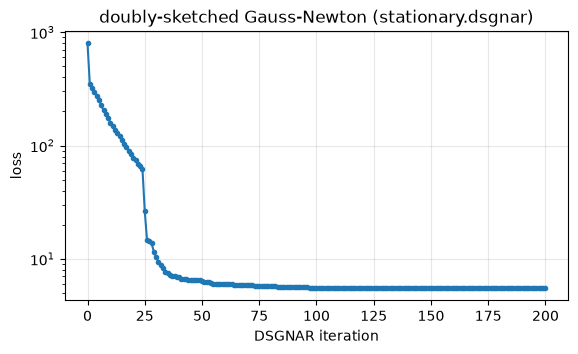

In [13]:
steps = [h["step"] for h in history]
losses = [h["loss"] for h in history]

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.semilogy(steps, losses, "o-", ms=3)
ax.set(xlabel="DSGNAR iteration", ylabel="loss",
       title="doubly-sketched Gauss-Newton (stationary.dsgnar)")
ax.grid(alpha=0.3)
plt.show()

In [14]:
# The same objective, minimised with Crunch's self-scaling Broyden instead of DSGNAR.
fun = jax.jit(objective._loss)
t0 = time.perf_counter()
res = minimize(fun, flat0, args=(), method="BFGS",
               options={"maxiter": QN_MAXITER,
                        "gtol": 1e-12,
                        "initial_H": jnp.eye(flat0.size, dtype=flat0.dtype),
                        "update_method": "ssbroyden2",
                        "initial_scale": True})
flat_qn = res.x
# Crunch's status codes: 0 = converged (|grad|_inf < gtol), 1 = maxiter reached,
# 2 = line search failed, 3 = line search failed inside the zoom stage.
STATUS = {0: "converged", 1: f"maxiter ({QN_MAXITER}) reached",
          2: "line search failed", 3: "line search failed (zoom failed)"}
print(f"SSBroyden: {int(res.nit)} iterations in {time.perf_counter() - t0:.1f}s | "
      f"loss {objective.loss(flat0):.6e} -> {float(res.fun):.6e} | "
      f"status {int(res.status)} ({STATUS.get(int(res.status), 'undefined')})")

best = flat if objective.loss(flat) <= objective.loss(flat_qn) else flat_qn
print(f"\nbest of the two: loss {objective.loss(best):.6e}")

SSBroyden: 4 iterations in 22.7s | loss 7.990652e+02 -> 2.496618e+02 | status 3 (line search failed (zoom failed))

best of the two: loss 5.506216e+00


reference: ldc_reference.npz | 16641 points | channels ['u', 'v', 'p']
  rel L2  u: 6.510e-01
  rel L2  v: 8.471e-01
  rel L2  p: 2.966e+00


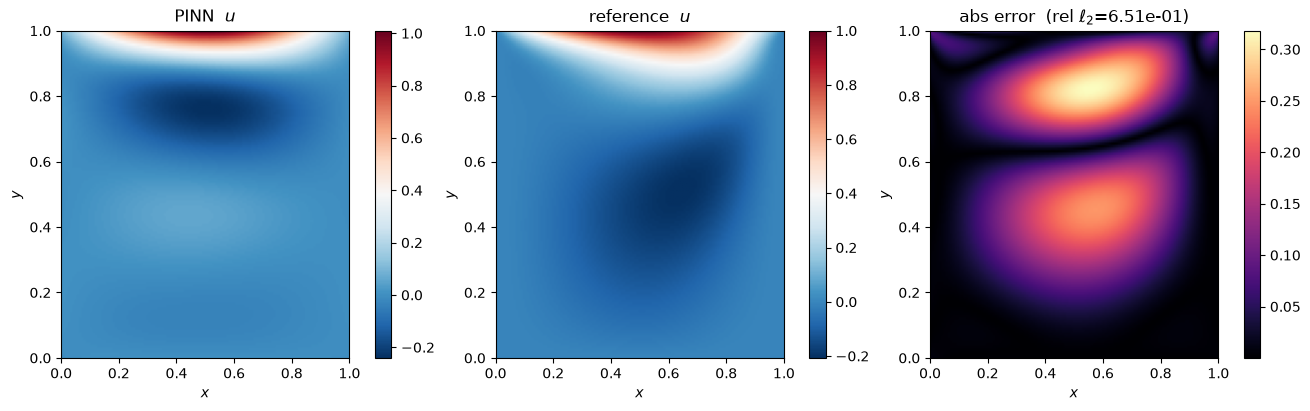

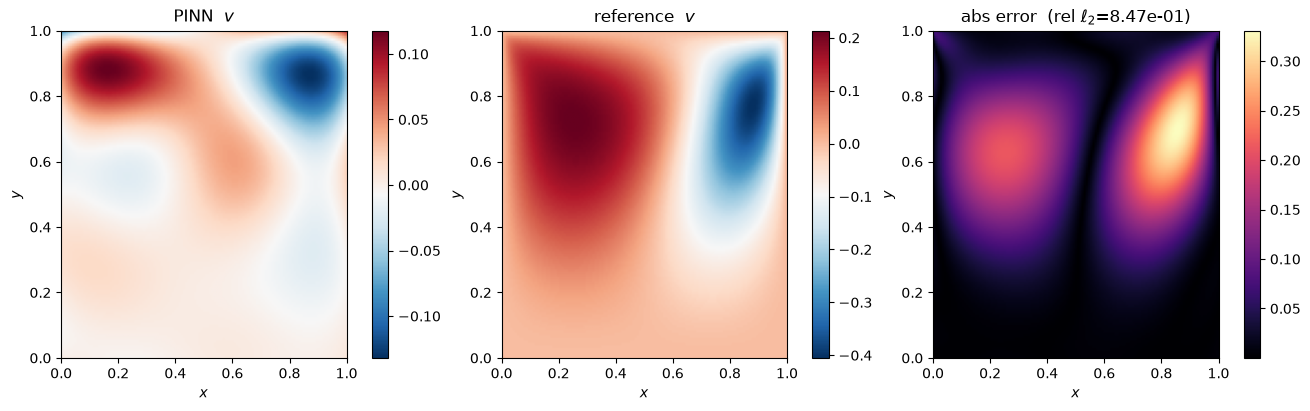

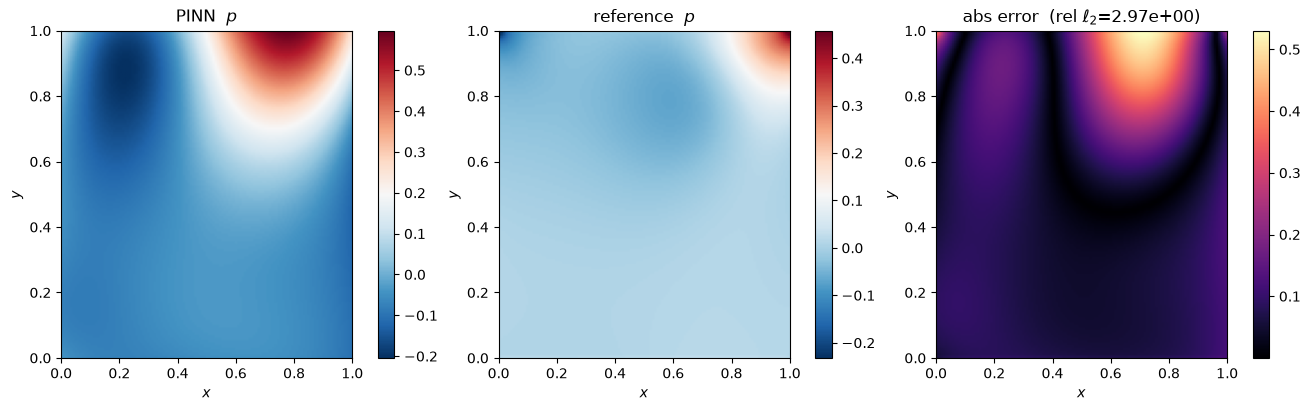

In [16]:
ref_path = REPO / "ldc" / "reference_gen" / "ldc_reference.npz"
if not ref_path.exists():
    raise FileNotFoundError(f"{ref_path} is missing -- run "
                            f"ldc/reference_gen/make_ldc_reference.py first")
ref = np.load(ref_path)
channels = [str(c) for c in ref["channels"]]
coords, exact = ref["coords"], ref["solution"]


def predict(params, pts):
    """Model output at arbitrary points, shape (n, out_dim)."""
    return np.asarray(jax.jit(jax.vmap(lambda c: forward(params, c)))(jnp.asarray(pts)))


params_best = unflatten(best)   # the optimisers carry flat vectors; the model wants the pytree

print(f"reference: {ref_path.name} | {coords.shape[0]} points | channels {channels}")
pred = predict(params_best, coords)
for i, ch in enumerate(channels):
    p, e = pred[:, i], exact[:, i]
    if ch == "p":
        p, e = p - p.mean(), e - e.mean()
    print(f"  rel L2  {ch}: {np.linalg.norm(p - e) / np.linalg.norm(e):.3e}")

x0, x1 = ref["plot_x0"], ref["plot_x1"]
extent = [x0[0], x0[-1], x1[0], x1[-1]]
grid_pts = np.stack(np.meshgrid(x0, x1, indexing="ij"), axis=-1).reshape(-1, 2)
pred_grid = predict(params_best, grid_pts).reshape(x0.size, x1.size, -1)

for i, ch in enumerate(channels):
    p = pred_grid[..., i]
    e = np.array(ref[f"plot_{ch}"])
    if ch == "p":
        p, e = p - p.mean(), e - e.mean()
    err = np.abs(p - e)
    rel = np.linalg.norm(p - e) / np.linalg.norm(e)

    fig, axs = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
    for ax, data, title, cmap in zip(
        axs, [p, e, err],
        [f"PINN  ${ch}$", f"reference  ${ch}$",
         f"abs error  (rel $\\ell_2$={rel:.2e})"],
        ["RdBu_r", "RdBu_r", "magma"],
    ):
        im = ax.imshow(data.T, origin="lower", aspect="auto", extent=extent, cmap=cmap)
        ax.set(xlabel="$x$", ylabel="$y$", title=title)
        fig.colorbar(im, ax=ax)
    plt.show()